# Minipix Counting Testing

Using this __[LSDB Scaling Workflows](https://docs.lsdb.io/en/latest/tutorials/pre_executed/scaling_workflows.html)__ tutorial to learn how to write a function to apply to partitions of a HATSed catalog, and the map_partitions tutorial to apply a function to all partitions.

Using the __[map_rows](https://docs.lsdb.io/en/latest/reference/api/lsdb.catalog.Catalog.map_rows.html#lsdb.catalog.Catalog.map_rows)__ method to apply a function that I write to the rows of a HATSed catalog partition, and the __[PixelSearch](https://docs.lsdb.io/en/latest/reference/api/lsdb.core.search.region_search.PixelSearch.html#)__ class to select a single catalog partition, and __[map_partitions]()__ to apply a function that I write to the partitions of a HATSed catalog.

In [1]:
import astropy.units as u
from dask.distributed import Client
import lsdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import time

from hdps.skymap import SegmentationScheme, TanSegmentLookup

# if using the hdps .venv, I had to do a 
# $ uv pip install "lsdb[full]>=0.8.1"     to use open_catalog() 
# $ uv pip install pandas                  (again, even tho it comes with hdps) to use the PixelSearch
# $ uv pip install -U memory_profiler      to test memory usage 

## Using hdps_skymap, explore sky tiling & minipix lookup for coordinates

### Load sky tiling schemes

In [11]:
# Load the default all-sky scheme (cached to ~/.hdps/skymap_cache/, according to according to https://github.com/argus-hdps/hdps/blob/main/docs/source/how_to/manage_tile_collections.rst)
scheme_allsky = SegmentationScheme.all_sky() # takes a few minutes 
    # -- first time running that in /home/kmfas, I got this:
    # No cache found at /home/kmfas/.hdps/skymap_cache/segscheme_tile1800p0_overlap28p125_ps0p87890625_ra0-360_dec-90-90.fits, generating new tiles...
    # Saving new scheme to cache: /home/kmfas/.hdps/skymap_cache/segscheme_tile1800p0_overlap28p125_ps0p87890625_ra0-360_dec-90-90.fits
    # Cached 170448 tiles to /home/kmfas/.hdps/skymap_cache/segscheme_tile1800p0_overlap28p125_ps0p87890625_ra0-360_dec-90-90.fits
    # -- after first time, I get this:
    # Loading SegmentationScheme from cache: /home/kmfas/.hdps/skymap_cache/segscheme_tile1800p0_overlap28p125_ps0p87890625_ra0-360_dec-90-90.fits
    # Loaded 170448 tiles from cache

Loading SegmentationScheme from cache: /home/kmfas/.hdps/skymap_cache/segscheme_tile1800p0_overlap28p125_ps0p87890625_ra0-360_dec-90-90.fits
Loaded 170448 tiles from cache


In [3]:
# Load partial sky tiling schemes
ra_center = 280 # degrees
dec_center = 20 # degrees

tile_size_default = 1800.0  # 2048 * (900/1024)       arcsec
overlap_arcsec_default = 28.125  # 32 * (900/1024)    arcsec
pixel_scale_default = 900 / 1024                    # arcsec

# 4-degree square tiling scheme 
radius_degree = 2
t0 = time.time()
scheme_4deg = SegmentationScheme(
    tile_size_arcsec=tile_size_default,
    overlap_arcsec=overlap_arcsec_default,
    pixel_scale=pixel_scale_default,
    ra_min=ra_center-radius_degree, ra_max=ra_center+radius_degree,
    dec_min=dec_center-radius_degree, dec_max=dec_center+radius_degree
)
scheme_4deg.generate_tiles()
t1 = time.time()
print(f"Created {len(scheme_4deg.tiles)} tile grid (scheme_4deg) in {(t1-t0):.4f} seconds")

Created 72 tile grid (scheme_4deg) in 0.0348 seconds


In [5]:
vars(scheme_4deg)

{'tile_size_arcsec': 1800.0,
 'overlap_arcsec': 28.125,
 'pixel_scale': 0.87890625,
 'dec_min': 18,
 'dec_max': 22,
 'ra_min': 278,
 'ra_max': 282,
 'tile_size_deg': 0.5,
 'overlap_deg': 0.0078125,
 'spacing_deg': 0.4921875,
 'npix': 2048,
 'tiles': [{'tile_id': 1,
   'ra_center': np.float64(278.25912229608326),
   'dec_center': 18.24609375,
   'ra_min': np.float64(277.99588694768124),
   'ra_max': np.float64(278.5223576444853),
   'dec_min': 17.99609375,
   'dec_max': 18.49609375,
   'npix_x': 2048,
   'npix_y': 2048,
   'cos_dec': np.float64(0.9497204745397203),
   'dec_band': 0,
   'ra_slot': 1},
  {'tile_id': 1,
   'ra_center': np.float64(278.77736688824973),
   'dec_center': 18.24609375,
   'ra_min': np.float64(278.5141315398477),
   'ra_max': np.float64(279.04060223665175),
   'dec_min': 17.99609375,
   'dec_max': 18.49609375,
   'npix_x': 2048,
   'npix_y': 2048,
   'cos_dec': np.float64(0.9497204745397203),
   'dec_band': 0,
   'ra_slot': 1},
  {'tile_id': 2,
   'ra_center': np

In [ ]:
# 100-degree square tiling scheme 
radius_degree = 50
t0 = time.time()
scheme_100deg = SegmentationScheme(
    tile_size_arcsec=tile_size_default,
    overlap_arcsec=overlap_arcsec_default,
    pixel_scale=pixel_scale_default,
    ra_min=ra_center-radius_degree, ra_max=ra_center+radius_degree,
    dec_min=dec_center-radius_degree, dec_max=dec_center+radius_degree
)
scheme_100deg.generate_tiles()
t1 = time.time()
print(f"Created {len(scheme_100deg.tiles)} tile grid (scheme_100deg) in {(t1-t0):.4f} seconds")

In [ ]:
# Replicate all-sky tiling scheme (will take forever......of course)
t0 = time.time()
scheme_allrep = SegmentationScheme(
    tile_size_arcsec=tile_size_default,
    overlap_arcsec=overlap_arcsec_default,
    pixel_scale=pixel_scale_default,
    dec_min=-90,
    dec_max=90,
    ra_min=0,
    ra_max=360
)
scheme_allrep.generate_tiles()
t1 = time.time()
print(f"Created {len(scheme_allrep.tiles)} tile grid (scheme_allrep) in {(t1-t0):.4f} seconds")

### Querying tile/minipix IDs with SegmentationScheme

In [96]:
# Look up tanseg ID and minipix index for a single position

#ra, dec = 83.633, 22.014  # Crab Pulsar
ra,dec = ra_center,dec_center

tile_id_allsky, minipix_idx_allsky = scheme_allsky.query_tile_id(ra, dec)
tile_id_4deg, minipix_idx_4deg = scheme_4deg.query_tile_id(ra, dec)
tile_id_100deg, minipix_idx_100deg = scheme_100deg.query_tile_id(ra, dec)
tile_id_allrep, minipix_idx_allrep = scheme_allrep.query_tile_id(ra, dec)

#print(f"for this source (Crab Nebula), tile ID = {tile_id_allsky}, minipix index = {minipix_idx_allsky}")
print(f"for this source, tile ID = {tile_id_allsky}, minipix index = {minipix_idx_allsky} (scheme_allsky)")
print(f".................tile ID = {tile_id_4deg}, minipix index = {minipix_idx_4deg} (scheme_4deg)")
print(f".................tile ID = {tile_id_100deg}, minipix index = {minipix_idx_100deg} (scheme_100deg)")
print(f".................tile ID = {tile_id_allrep}, minipix index = {minipix_idx_allrep} (scheme_allrep)")

for this source, tile ID = 321655, minipix index = 4038 (scheme_allsky)
.................tile ID = 5764, minipix index = 2347 (scheme_4deg)
.................tile ID = 146975, minipix index = 394 (scheme_100deg)
.................tile ID = 321655, minipix index = 4038 (scheme_allrep)


In [98]:
# Can you look up tanseg IDs and minipix indices for multiple positions at once? (yes)
ras = np.array([200,35])
decs = np.array([63,-23])
tile_ids, minipix_idxs = scheme_allsky.query_tile_id(ras, decs)
print(type(tile_ids),type(minipix_idxs))

<class 'numpy.ndarray'> <class 'numpy.ndarray'>


In [110]:
# How long does it take for many? (not too long for 1000)
ras = np.repeat(np.arange(0,300,1),4)[:1000]
decs = np.repeat(np.arange(-85,85,1),6)[:1000]
tile_ids,minipix_idxs = scheme.query_tile_id(ras, decs)

In [5]:
# Get center coordinates of a tile 
tile_id = 270906
center_minipix_idx = 2080 # always center minipix
ra_center, dec_center = scheme_4deg.tile_id_to_radec(tile_id, center_minipix_idx)
print(f"Center Minipix of tanseg center coords: RA={ra_center:.4f}°, Dec={dec_center:.4f}°")

Center Minipix of tanseg center coords: RA=66338.0111°, Dec=69.4648°


### Lookup tile/minipix IDs with TanSegmentLookup instead of loading the SegmentationScheme (faster):

In [14]:
from hdps.skymap import TanSegmentActivationManager, TanSegmentLookup
import astropy.units as u

tile_size_default = 1800.0  # 2048 * (900/1024)       arcsec
overlap_arcsec_default = 28.125  # 32 * (900/1024)    arcsec
pixel_scale_default = 900 / 1024                    # arcsec

# Define a TanSegmentLookup
lookup = TanSegmentLookup(
    spacing_deg=(tile_size_default-overlap_arcsec_default)/3600,          # tile_size - overlap in degrees
    pixel_scale_deg=pixel_scale_default/3600  # arcsec to degrees
) 


# Try out batch lookup (millions per second) against SegmentationScheme query to make sure tile/minipix ids are the same for both
ra = np.array([279.23, 10.68, 83.63])
dec = np.array([38.78, 41.27, 22.01])
tiles_lookup, minipixes_lookup = lookup.query_batch(ra, dec)
tiles_scheme, minipixes_scheme = scheme_allsky.query_tile_id(ra,dec)
print("Tile/Minipix IDs from lookup = ",tiles_lookup,minipixes_lookup)
print("Tile/Minipix IDs from scheme = ",tiles_scheme,minipixes_scheme)

Tile/Minipix IDs from lookup =  [377722 384496 328478] [639 846 383]
Tile/Minipix IDs from scheme =  [377722 384496 328478] [639 846 383]


## Using lsdb, load in some catalogs

### Get a single pixel/partition in a HATSed catalog

#### My HATS-ed 0.1% of ATLAS-Refcat2 on Aurora:

In [79]:
atlas_path = "/net/scratch/kmfas/atlas_refcat2/atlas_0_01"
atlas = lsdb.open_catalog(atlas_path,filters=[["dec",">","-20"]])
stats = atlas.per_pixel_statistics(include_columns=["ra","dec"], include_stats=["row_count"])
stats.sort_values(["ra: row_count"], ascending=False).head(5)

,ra: row_count,dec: row_count
"Order: 7, Pixel: 165870",1000,1000
"Order: 7, Pixel: 114987",1000,1000
"Order: 6, Pixel: 13024",1000,1000
"Order: 7, Pixel: 114822",1000,1000
"Order: 7, Pixel: 115874",1000,1000


In [ ]:
# Only load data from one single partition in the cat
ordr = 3 #7
pixid = 368 #165870
atlas_path = "/net/scratch/kmfas/atlas_refcat2/atlas_0_01"
atlas_pix_lookup = lsdb.open_catalog(atlas_path,search_filter=lsdb.PixelSearch((ordr,pixid))) #PixelSearch((order,pixelid))

# Load the data
atlas_single_part = atlas_pix_lookup.compute()

# How much space in memory does this single partition take up?
atlas_single_part.info()

Computing Catalog:   0%|          | 0/49 [00:00<?, ?it/s]

<class 'nested_pandas.nestedframe.core.NestedFrame'>
Index: 9993 entries, 1657325513743157866 to 1661827954336513510
Data columns (total 12 columns):
 #   Column      Non-Null Count  Dtype          
---  ------      --------------  -----          
 0   Unnamed: 0  9993 non-null   int64[pyarrow] 
 1   ra          9993 non-null   double[pyarrow]
 2   dec         9993 non-null   double[pyarrow]
 3   parallax    9993 non-null   double[pyarrow]
 4   pmra        9993 non-null   double[pyarrow]
 5   pmdec       9993 non-null   double[pyarrow]
 6   g           9993 non-null   double[pyarrow]
 7   r           9993 non-null   double[pyarrow]
 8   i           9993 non-null   double[pyarrow]
 9   h32         9993 non-null   int64[pyarrow] 
 10  h64         9993 non-null   int64[pyarrow] 
 11  h256        9993 non-null   int64[pyarrow] 
dtypes: double[pyarrow](8), int64[pyarrow](4)
memory usage: 1.0 MB


In [18]:
# Test: Try out querying IDs with SegmentationScheme (yes, it works and the output is still numpy ndarrays)
tanseg_ids, minipix_idxs = scheme_allsky.query_tile_id(atlas_single_part['ra'],atlas_single_part['dec'])
print(type(tanseg_ids),type(minipix_idxs))

<class 'numpy.ndarray'> <class 'numpy.ndarray'>


In [ ]:
# Test: Try out looking up IDs with TanSegmentLookup (yes, it works and the output is still numpy ndarrays)
tanseg_ids, local_indices = lookup.query_batch(atlas_single_part['ra'],atlas_single_part['dec'],)
print(type(tanseg_ids),type(local_indices))

<class 'numpy.ndarray'> <class 'numpy.ndarray'>


#### ZTF DR14 object table (~same length at ATLAS-Refcat2), available thru the LSDB data cloud:

In [76]:
ztf_path = "https://data.lsdb.io/hats/ztf_dr14"
ztf_full = lsdb.open_catalog(ztf_path)
stats = ztf_full.per_pixel_statistics(include_columns=["ra","dec"], include_stats=["row_count"])
stats.sort_values(["ra: row_count"], ascending=False).head(5)

,ra: row_count,dec: row_count
"Order: 3, Pixel: 181",998280,998280
"Order: 3, Pixel: 100",996792,996792
"Order: 5, Pixel: 3586",996702,996702
"Order: 4, Pixel: 2011",996552,996552
"Order: 5, Pixel: 3596",996124,996124


In [33]:
# Only load data from one single partition in the cat
ztf_pix_lookup = lsdb.open_catalog(ztf_path,search_filter=lsdb.PixelSearch((3, 181))) #PixelSearch((order,pixelid))

# Load the data
ztf_single_part = ztf_pix_lookup.compute()

# How much space in memory does this single partition take up?
ztf_single_part.info()

<class 'nested_pandas.nestedframe.core.NestedFrame'>
Index: 998280 entries, 815151537798436627 to 819655131287911111
Data columns (total 12 columns):
 #   Column           Non-Null Count   Dtype          
---  ------           --------------   -----          
 0   ps1_objid        998280 non-null  int64[pyarrow] 
 1   ra               998280 non-null  double[pyarrow]
 2   dec              998280 non-null  double[pyarrow]
 3   ps1_gMeanPSFMag  998280 non-null  double[pyarrow]
 4   ps1_rMeanPSFMag  998280 non-null  double[pyarrow]
 5   ps1_iMeanPSFMag  998280 non-null  double[pyarrow]
 6   nobs_g           998280 non-null  int32[pyarrow] 
 7   nobs_r           998280 non-null  int32[pyarrow] 
 8   nobs_i           998280 non-null  int32[pyarrow] 
 9   mean_mag_g       589973 non-null  double[pyarrow]
 10  mean_mag_r       933559 non-null  double[pyarrow]
 11  mean_mag_i       843007 non-null  double[pyarrow]
dtypes: double[pyarrow](8), int32[pyarrow](3), int64[pyarrow](1)
memory usage: 8

#### Gaia DR3  (partition with least amt of sources)

In [ ]:
gaia_path = "https://data.lsdb.io/hats/gaia_dr3"
gaia3_full = lsdb.open_catalog(gaia_path)
stats = gaia3_full.per_pixel_statistics(include_columns=["ra","dec"], include_stats=["row_count"])
stats.sort_values(["ra: row_count"], ascending=False).head(5) # show partitions with least amnt of sources

,ra: row_count,dec: row_count
"Order: 2, Pixel: 0",726621,726621
"Order: 2, Pixel: 1",1485249,1485249
"Order: 2, Pixel: 2",837288,837288
"Order: 2, Pixel: 3",1745814,1745814
"Order: 3, Pixel: 16",640850,640850


np.int64(726621)

In [ ]:
# Only load data from one single partition in the cat (smallest one!)
ordr = 5 
pixid = 8283
gaia_path = "https://data.lsdb.io/hats/gaia_dr3"
gaia_pix_lookup = lsdb.open_catalog(gaia_path,search_filter=lsdb.PixelSearch((ordr,pixid))) #PixelSearch((order,pixelid))

# Load the data
gaia_single_part = gaia_pix_lookup.compute()

# How much space in memory does this single partition take up?
gaia_single_part.info()

<class 'nested_pandas.nestedframe.core.NestedFrame'>
Index: 130911 entries, 2331457232233619679 to 2331738706130260199
Columns: 152 entries, solution_id to libname_gspphot
dtypes: bool[pyarrow](12), double[pyarrow](13), float[pyarrow](93), int16[pyarrow](23), int64[pyarrow](3), int8[pyarrow](5), string[pyarrow](3)
memory usage: 79.2 MB


### Get an associated order/pixel of an RA,Dec coord 

In [ ]:
from lsdb.core.search.region_search import PixelSearch

# search a pixel from RA,Dec
search_object = PixelSearch.from_radec(280, 20)
gaia3_search = gaia3_full.search(search_object)
pxl = gaia3_search.get_healpix_pixels()
gaia3_pxl = gaia3_full.get_partition(pxl[0],pxl[1])

4

72.23216246159426 -65.33717984418101


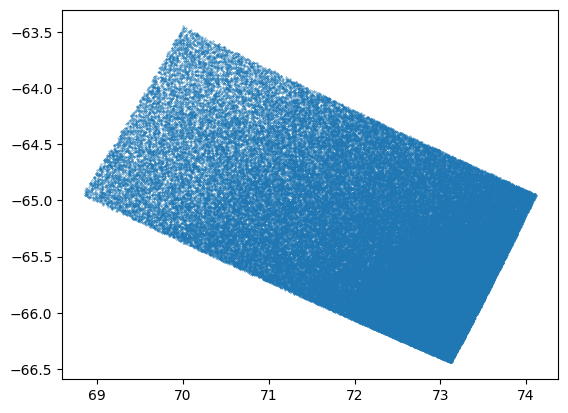

In [43]:
print(np.mean(gaia_single_part['ra']),np.mean(gaia_single_part['dec']))
plt.scatter(gaia_single_part['ra'],gaia_single_part['dec'],s=0.1)
plt.show()

## Get a few partitions of a cat for testing: Gaia DR3 cone search

In [ ]:
gaia_path = "https://data.lsdb.io/hats/gaia_dr3"
#catalog_root = "/epyc/data3/hats/catalogs"
gaia3 = lsdb.open_catalog(
    gaia_path,
    search_filter=lsdb.ConeSearch(ra=280, dec=20, radius_arcsec=10 * 3600), #at RA,Dec = 280,20; 2deg = 4partitions; 10deg = 56 partitions
    columns=[
        "source_id",
        "ra",
        "dec",
        "phot_g_mean_mag",
    ],
)
gaia3.npartitions

56

## Applying functions to HATS-ed catalogs loaded with LSDB

### map_rows(): Apply a function to the rows catalog partition

Using this __[LSDB Scaling Workflows](https://docs.lsdb.io/en/latest/tutorials/pre_executed/scaling_workflows.html)__ tutorial

Define a function to calculate the minipix indices of source coordinates from the catalog

In [7]:
def calc_minipix_idx_rows(cat_df,scheme):
    '''
    Calculate the unique minipix indices & tanseg IDs for sources in 
    a catalog dataframe cat_df (a partition of a HATSed catalog loaded by lsdb)

    Arguments:
    ----------
    cat_df (dataframe)
    scheme (hdps.skymap.SegmentationScheme (all-sky))
    
    Returns:
    ---------


    '''
    def _get_ids(ra,dec,**kwargs):
        tanseg_id, minipix_idx = scheme.query_tile_id(ra, dec)
        #print(tanseg_id,minipix_idx)
        return tanseg_id, minipix_idx

    ids = cat_df.map_rows(_get_ids,
                          columns=["ra","dec"],
                          row_container="args", # to pass in columns as arguments to _get_ids()
                          output_names=["tanseg_id","minipix_idx"],
                          append_columns=True) 
    
    return ids 

Apply the function to the single partition you loaded

In [35]:
ids_atlas = calc_minipix_idx_rows(atlas_single_part,scheme)
print(len(ids_atlas)," rows in ATLAS partition, ",len(np.unique(ids_atlas['minipix_idx']))," unique minipix IDXs")
ids_atlas

9993  rows in ATLAS partition,  3608  unique minipix IDXs


,Unnamed: 0,ra,dec,parallax,pmra,pmdec,g,r,i,h32,h64,h256,tanseg_id,minipix_idx
_healpix_29,,,,,,,,,,,,,,
1657325513743157866,23020,90.006208,0.091356,1.13,-1.42,-0.2,17.496,16.517,16.01,5888,23552,376832,263703,2216
1657325536932057554,33355,89.985974,0.09594,0.69,-0.52,5.82,17.479,16.626,16.181,5888,23552,376832,263703,2282
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1661827272758578812,119567,90.013518,9.480139,1.1,5.27,-3.58,19.72,18.446,17.76,5903,23615,377855,291060,2501
1661827954336513510,201498,89.947741,9.530316,1.41,1.81,0.18,20.508,19.446,18.91,5903,23615,377855,291060,2894


In [36]:
ids_ztf = calc_minipix_idx_rows(ztf_single_part,scheme)
print(len(ids_ztf),"rows in ZTF partition, ",len(np.unique(ids_ztf['minipix_idx']))," unique minipix IDXs")
ids_ztf

998280 rows in ZTF partition,  1127  unique minipix IDXs


,ps1_objid,ra,dec,ps1_gMeanPSFMag,ps1_rMeanPSFMag,ps1_iMeanPSFMag,nobs_g,nobs_r,nobs_i,mean_mag_g,mean_mag_r,mean_mag_i,tanseg_id,minipix_idx
_healpix_29,,,,,,,,,,,,,,
815151537798436627,180532520164394060,252.016516,60.444418,20.789499,20.4774,20.2936,538,800,80,20.788663,20.414265,20.261011,440893,831
815151538064298522,180532520211764167,252.021176,60.444471,20.771999,19.726101,19.130199,595,1050,115,20.606813,19.338874,18.829586,440893,831
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
819655123273116552,194852699912566007,269.991257,72.379356,-999.0,21.9048,20.829201,0,32,32,<NA>,21.168079,20.508618,475366,1717
819655131287911111,194862699866110723,269.986247,72.38338,-999.0,21.747999,20.740101,1,18,45,21.935329,21.316098,20.408695,475366,1781


minipix_indices, tanseg_ids = calc_minipix_idx(cat_single_part)

In [37]:
from memory_profiler import memory_usage

def calc_minipix_idx_mem():

    return calc_minipix_idx(atlas_single_part,scheme)

mem = max(memory_usage(proc=calc_minipix_idx_mem))

print("Maximum memory used for ATLAS fraction: {} MiB".format(mem))

Maximum memory used for ATLAS fraction: 7734.734375 MiB


In [38]:
from memory_profiler import memory_usage

def calc_minipix_idx_mem():

    return calc_minipix_idx(ztf_single_part,scheme)

mem = max(memory_usage(proc=calc_minipix_idx_mem))

print("Maximum memory used for ZTF: {} MiB".format(mem))

Maximum memory used for ZTF: 7833.16015625 MiB


#### do not run this - it came from the scaling workflows example, but doesn't work on an entire HATSed catalog like i thought it would!
with Client(n_workers=4, memory_limit="8GB", threads_per_worker=1) as client:
    # We can use the map_partitions method to apply our function to each pixel
    # Results from single pixel operations can be used for the meta, but use head(0) to not pass along the full data
    full_res_0_001 = atlas.map_partitions(calc_minipix_idx, meta=atlas_single_part.head(0),scheme=scheme)
    full_res_0_001.write_catalog(base_catalog_path="/net/scratch/kmfas/atlas_refcat2/",catalog_name="atlas_0_001_minipix_idx") # it's the full cat so don't compute!  write directly to disk, girl

### Apply a function to the partitions of a HATSed catalog with map_partitions 

Using this __[LSDB map_partitions tutorial](https://docs.lsdb.io/en/latest/tutorials/pre_executed/map_partitions.html)__

What kind of function can I give to map_partitions?
- First parameter of function = pandas df (the catalog partition)
- Other parameters can be passed in as keyword arguments to .map_partitions

Catalog is loaded lazily, so map_partitions also returns a lazily-loaded object

Define function to calculate tile/minipix ids

In [30]:
def square_a_column(dframe,target_column):
    """
    Simple test function to square the values in a column of a dataframe

    Arguments
    ---------
    dframe (DataFrame) 
        A source catalog with columns for RA and Dec

    target_column (str)
        The name of the column of values you want to square (must be dtype int or float)
    
    Returns
    -------
    dframe (DataFrame)
        The catalog with added column of squared values from target_column (name = "<target_column>_sq")
    """
    col_squared = dframe[target_column] ** 2
    dframe[target_column+"_sq"] = col_squared
    return dframe


def calculate_minipix_idx(dframe,scheme,ra_column,dec_column):
    """
    A function that calculates the tile IDs & minipix indices of the rows (sources) of a dataframe
    
    Arguments
    ---------
    dframe (DataFrame) 
        A source catalog with columns for RA and Dec
    
    scheme (SegmentationScheme)
        A sky tiling scheme with tiles and minipix

    ra_column (str)
        the name of dframe's RA column

    dec_column(str)
        the name of dframe's Dec column
    
    Returns
    -------
    dframe (DataFrame)
        either with or without added tile_id and minipix_idx columns, failure occurs either way
    """
    print("calculating IDS....")
    tile_ids,minipix_idxs = scheme.query_tile_id(dframe[ra_column],dframe[dec_column])
    print("calculated IDS....")
    # *******failure occurs whether or not the following 2 lines are commented out, i.e. the dframe is edited:
    dframe['tile_id'] = tile_ids
    dframe['minipix_idx'] = minipix_idxs
    #print("added columns to dframe")
    return dframe 


def lookup_minipix_idx(dframe,lookup,ra_column,dec_column,verbose=True):
    """
    A function that calculates the tile IDs & minipix indices of the rows (sources) of a dataframe
    
    Arguments
    ---------
    dframe (DataFrame) 
        A source catalog with columns for RA and Dec
    
    lookup (TanSegmentLookup)

    ra_column (str)
        the name of dframe's RA column

    dec_column(str)
        the name of dframe's Dec column
    
    Returns
    -------
    dframe (DataFrame)
        either with or without added tile_id and minipix_idx columns, failure occurs either way
    """
    if verbose: print("calculating IDS....")
    tile_ids,minipix_idxs = lookup.query_batch(dframe[ra_column],dframe[dec_column])
    if verbose: print("calculated IDS....")
    dframe['tile_id'] = tile_ids
    dframe['minipix_idx'] = minipix_idxs
    if verbose: print("added columns to dframe")
    return dframe 

### map_partitions(): Apply functions to catalog partition using sky tiling schemes and lookup

In [31]:
# using 4deg tiling scheme:
t0 = time.time()
ids_4deg = gaia_pix_lookup.map_partitions(calculate_minipix_idx,scheme_4deg,"ra","dec") # took 14 min first time
t1 = time.time()
ids_4deg_data = ids_4deg.compute() 
t2 = time.time()
print(f"time to map_partitions with 4deg scheme = {(t1-t0):.4f} sec")
print(f"time to compute = {(t2-t1):.4f} sec")

calculating IDS....
calculated IDS....
calculating IDS....
calculated IDS....
calculating IDS....
calculated IDS....
time to map_partitions with 4deg scheme = 1.0398 sec
time to compute = 8.4348 sec


In [84]:
ids.head(5)

calculating IDS....
calculated IDS....


,solution_id,designation,source_id,random_index,ref_epoch,ra,ra_error,dec,dec_error,parallax,parallax_error,parallax_over_error,pm,pmra,pmra_error,pmdec,pmdec_error,ra_dec_corr,ra_parallax_corr,ra_pmra_corr,ra_pmdec_corr,dec_parallax_corr,dec_pmra_corr,dec_pmdec_corr,parallax_pmra_corr,parallax_pmdec_corr,pmra_pmdec_corr,astrometric_n_obs_al,astrometric_n_obs_ac,astrometric_n_good_obs_al,astrometric_n_bad_obs_al,astrometric_gof_al,astrometric_chi2_al,astrometric_excess_noise,astrometric_excess_noise_sig,astrometric_params_solved,astrometric_primary_flag,nu_eff_used_in_astrometry,pseudocolour,pseudocolour_error,ra_pseudocolour_corr,dec_pseudocolour_corr,parallax_pseudocolour_corr,pmra_pseudocolour_corr,pmdec_pseudocolour_corr,astrometric_matched_transits,visibility_periods_used,astrometric_sigma5d_max,matched_transits,new_matched_transits,matched_transits_removed,ipd_gof_harmonic_amplitude,ipd_gof_harmonic_phase,ipd_frac_multi_peak,ipd_frac_odd_win,ruwe,scan_direction_strength_k1,scan_direction_strength_k2,scan_direction_strength_k3,scan_direction_strength_k4,scan_direction_mean_k1,scan_direction_mean_k2,scan_direction_mean_k3,scan_direction_mean_k4,duplicated_source,phot_g_n_obs,phot_g_mean_flux,phot_g_mean_flux_error,phot_g_mean_flux_over_error,phot_g_mean_mag,phot_bp_n_obs,phot_bp_mean_flux,phot_bp_mean_flux_error,phot_bp_mean_flux_over_error,phot_bp_mean_mag,phot_rp_n_obs,phot_rp_mean_flux,phot_rp_mean_flux_error,phot_rp_mean_flux_over_error,phot_rp_mean_mag,phot_bp_rp_excess_factor,phot_bp_n_contaminated_transits,phot_bp_n_blended_transits,phot_rp_n_contaminated_transits,phot_rp_n_blended_transits,phot_proc_mode,bp_rp,bp_g,g_rp,radial_velocity,radial_velocity_error,rv_method_used,rv_nb_transits,rv_nb_deblended_transits,rv_visibility_periods_used,rv_expected_sig_to_noise,rv_renormalised_gof,rv_chisq_pvalue,rv_time_duration,rv_amplitude_robust,rv_template_teff,rv_template_logg,rv_template_fe_h,rv_atm_param_origin,vbroad,vbroad_error,vbroad_nb_transits,grvs_mag,grvs_mag_error,grvs_mag_nb_transits,rvs_spec_sig_to_noise,phot_variable_flag,l,b,ecl_lon,ecl_lat,in_qso_candidates,in_galaxy_candidates,non_single_star,has_xp_continuous,has_xp_sampled,has_rvs,has_epoch_photometry,has_epoch_rv,has_mcmc_gspphot,has_mcmc_msc,in_andromeda_survey,classprob_dsc_combmod_quasar,classprob_dsc_combmod_galaxy,classprob_dsc_combmod_star,teff_gspphot,teff_gspphot_lower,teff_gspphot_upper,logg_gspphot,logg_gspphot_lower,logg_gspphot_upper,mh_gspphot,mh_gspphot_lower,mh_gspphot_upper,distance_gspphot,distance_gspphot_lower,distance_gspphot_upper,azero_gspphot,azero_gspphot_lower,azero_gspphot_upper,ag_gspphot,ag_gspphot_lower,ag_gspphot_upper,ebpminrp_gspphot,ebpminrp_gspphot_lower,ebpminrp_gspphot_upper,libname_gspphot
_healpix_29,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2331457232233619679,1636148068921376768,Gaia DR3 4662914468485771904,4662914468485771904,444834410,2016.0,73.122743,0.84305,-66.442502,0.666002,-0.871247,0.693566,-1.256184,0.622678,-0.070953,1.638015,-0.618622,0.929693,0.171234,0.233567,0.385693,-0.288868,0.09851,0.019093,-0.215326,0.034396,-0.232136,-0.321577,166,0,166,0,-0.52641,155.523071,0.0,0.0,95,False,<NA>,1.695128,0.26138,-0.508823,-0.356429,-0.298226,-0.192573,0.303675,19,15,2.341945,21,5,0,0.025945,108.991585,0,0,0.968656,0.348181,0.247234,0.164925,0.320862,-78.461929,-3.312907,49.219101,2.609366,False,164,104.578953,0.98909,105.732452,20.638756,20,70.593225,5.418808,13.027444,20.716635,17,51.842902,10.589202,4.895827,20.461172,1.170753,0,0,0,0,0,0.255463,0.077879,0.177584,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,NOT_AVAILABLE,277.365668,-36.470937,353.25145,-83.2901,False,False,0,False,False,False,False,False,False,False,False,0.113796,0.0,0.886203,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<

In [ ]:
# using 100deg scheme:
t0 = time.time()
ids_100deg = gaia_pix_lookup.map_partitions(calculate_minipix_idx,scheme_100deg,"ra","dec") # took 7 min for the 100deg scheme
t1 = time.time()
ids_100deg_data = ids_100deg.compute()
t2 = time.time()
print(f"time to map_partitions with 100deg scheme = {(t1-t0):.4f} sec")
print(f"time to compute = {(t2-t1):.4f} sec")

calculating IDS....
calculated IDS....
calculating IDS....
calculated IDS....


,solution_id,designation,source_id,random_index,ref_epoch,ra,ra_error,dec,dec_error,parallax,parallax_error,parallax_over_error,pm,pmra,pmra_error,pmdec,pmdec_error,ra_dec_corr,ra_parallax_corr,ra_pmra_corr,ra_pmdec_corr,dec_parallax_corr,dec_pmra_corr,dec_pmdec_corr,parallax_pmra_corr,parallax_pmdec_corr,pmra_pmdec_corr,astrometric_n_obs_al,astrometric_n_obs_ac,astrometric_n_good_obs_al,astrometric_n_bad_obs_al,astrometric_gof_al,astrometric_chi2_al,astrometric_excess_noise,astrometric_excess_noise_sig,astrometric_params_solved,astrometric_primary_flag,nu_eff_used_in_astrometry,pseudocolour,pseudocolour_error,ra_pseudocolour_corr,dec_pseudocolour_corr,parallax_pseudocolour_corr,pmra_pseudocolour_corr,pmdec_pseudocolour_corr,astrometric_matched_transits,visibility_periods_used,astrometric_sigma5d_max,matched_transits,new_matched_transits,matched_transits_removed,ipd_gof_harmonic_amplitude,ipd_gof_harmonic_phase,ipd_frac_multi_peak,ipd_frac_odd_win,ruwe,scan_direction_strength_k1,scan_direction_strength_k2,scan_direction_strength_k3,scan_direction_strength_k4,scan_direction_mean_k1,scan_direction_mean_k2,scan_direction_mean_k3,scan_direction_mean_k4,duplicated_source,phot_g_n_obs,phot_g_mean_flux,phot_g_mean_flux_error,phot_g_mean_flux_over_error,phot_g_mean_mag,phot_bp_n_obs,phot_bp_mean_flux,phot_bp_mean_flux_error,phot_bp_mean_flux_over_error,phot_bp_mean_mag,phot_rp_n_obs,phot_rp_mean_flux,phot_rp_mean_flux_error,phot_rp_mean_flux_over_error,phot_rp_mean_mag,phot_bp_rp_excess_factor,phot_bp_n_contaminated_transits,phot_bp_n_blended_transits,phot_rp_n_contaminated_transits,phot_rp_n_blended_transits,phot_proc_mode,bp_rp,bp_g,g_rp,radial_velocity,radial_velocity_error,rv_method_used,rv_nb_transits,rv_nb_deblended_transits,rv_visibility_periods_used,rv_expected_sig_to_noise,rv_renormalised_gof,rv_chisq_pvalue,rv_time_duration,rv_amplitude_robust,rv_template_teff,rv_template_logg,rv_template_fe_h,rv_atm_param_origin,vbroad,vbroad_error,vbroad_nb_transits,grvs_mag,grvs_mag_error,grvs_mag_nb_transits,rvs_spec_sig_to_noise,phot_variable_flag,l,b,ecl_lon,ecl_lat,in_qso_candidates,in_galaxy_candidates,non_single_star,has_xp_continuous,has_xp_sampled,has_rvs,has_epoch_photometry,has_epoch_rv,has_mcmc_gspphot,has_mcmc_msc,in_andromeda_survey,classprob_dsc_combmod_quasar,classprob_dsc_combmod_galaxy,classprob_dsc_combmod_star,teff_gspphot,teff_gspphot_lower,teff_gspphot_upper,logg_gspphot,logg_gspphot_lower,logg_gspphot_upper,mh_gspphot,mh_gspphot_lower,mh_gspphot_upper,distance_gspphot,distance_gspphot_lower,distance_gspphot_upper,azero_gspphot,azero_gspphot_lower,azero_gspphot_upper,ag_gspphot,ag_gspphot_lower,ag_gspphot_upper,ebpminrp_gspphot,ebpminrp_gspphot_lower,ebpminrp_gspphot_upper,libname_gspphot
npartitions=1,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
"Order: 5, Pixel: 8283",int64[pyarrow],string[pyarrow],int64[pyarrow],int64[pyarrow],double[pyarrow],double[pyarrow],float[pyarrow],double[pyarrow],float[pyarrow],double[pyarrow],float[pyarrow],float[pyarrow],float[pyarrow],double[pyarrow],float[pyarrow],double[pyarrow],float[pyarrow],float[pyarrow],float[pyarrow],float[pyarrow],float[pyarrow],float[pyarrow],float[pyarrow],float[pyarrow],float[pyarrow],float[pyarrow],float[pyarrow],int16[pyarrow],int16[pyarrow],int16[pyarrow],int16[pyarrow],float[pyarrow],float[pyarrow],float[pyarrow],float[pyarrow],int8[pyarrow],bool[pyarrow],float[pyarrow],float[pyarrow],float[pyarrow],float[pyarrow],float[pyarrow],float[pyarrow],float[pyarrow],float[pyarrow],int16[pyarrow],int16[pyarrow],float[pyarrow],int16[pyarrow],int16[pyarrow],int16[pyarrow],float[pyarrow],float[pyarrow],int8[pyarrow],int8[pyarrow],float[pyarrow],float[pyarrow],float[pyarrow],float[pyarrow],float[pyarrow],float[pyarrow],float[pyarrow],float[pyarrow],float[pyarrow],bool[pyarrow],int16[pyarrow],double[pyarrow],float[pyarrow],float[pyarrow],float[pyarrow],int16[pyar

In [ ]:
# using allrep scheme (fails like allsky scheme, never completes):
t0 = time.time()
ids_allrep = gaia_pix_lookup.map_partitions(calculate_minipix_idx,scheme_allrep,"ra","dec") # took 7 min for the 100deg scheme
t1 = time.time()
ids_allrep_data = ids_allrep.compute()
t2 = time.time()
print(f"time to map_partitions with allsky scheme = {(t1-t0):.4f} sec")
print(f"time to compute = {(t2-t1):.4f} sec")

calculating IDS....
calculated IDS....


In [34]:
## doesn't work with SegmentationScheme
#g_scheme = gaia_pix_lookup.map_partitions(calculate_minipix_idx,scheme_allsky,"ra","dec")
#g_scheme.compute()

# works with TanSegmentLookup
t0 = time.time()
g_lookup = gaia_pix_lookup.map_partitions(lookup_minipix_idx,lookup,"ra","dec")
t1 = time.time()
g_lookup_data = g_lookup.compute()
t2 = time.time()

print(f"time to lookup IDS = {(t1-t0):.4f} seconds")
print(f"time to compute resulting df = {(t2-t1):.4f} seconds")

calculating IDS....
calculated IDS....
added columns to dframe
calculating IDS....
calculated IDS....
added columns to dframe


calculating IDS....
calculated IDS....
added columns to dframe
time to lookup IDS = 0.3749 seconds
time to compute resulting df = 4.5853 seconds


## Testing out that meta argument of map_partitions()

In [83]:
def find_stats_needs_meta(df, pixel, target_column=""):
    c = df[target_column]
    min_val = c.min()
    max_val = c.max()
    # WARNING! c.count() == 0 when passed an empty DataFrame.
    # But meta= will come to the rescue.
    mean_val = c.sum() / c.count()
    return pd.DataFrame(
        [
            {
                "pixel": pixel,
                f"{target_column}_min": min_val,
                f"{target_column}_max": max_val,
                f"{target_column}_mean": mean_val,
            }
        ]
    )

output_meta = pd.DataFrame(
    {
        "pixel": [],
        "phot_g_mean_mag_min": [],
        "phot_g_mean_mag_max": [],
        "phot_g_mean_mag_mean": [],
    }
)

In [84]:
unrealized = gaia3.map_partitions(
    find_stats_needs_meta,
    include_pixel=True,
    # Keyword arguments after 'include_pixel=' are passed to your function.
    target_column="phot_g_mean_mag",
    # Here we give Dask the hint it needs to avoid giving us an empty frame
    meta=output_meta,
)

In [85]:
result = unrealized.compute()
result

,pixel,phot_g_mean_mag_min,phot_g_mean_mag_max,phot_g_mean_mag_mean
0,"Order: 4, Pixel: 2944",8.154537,22.033451,19.083840
0,"Order: 4, Pixel: 2945",5.508409,22.345751,19.094207
0,"Order: 4, Pixel: 2946",6.264917,22.076380,19.102860
0,"Order: 4, Pixel: 2947",6.154421,21.986425,19.119143


In [82]:
from dask.dataframe.utils import make_meta

output_meta = make_meta(calc_minipix_idx(h5.head(1),scheme))
output_meta

,source_id,ra,dec,phot_g_mean_mag,tanseg_id,minipix_idx
_healpix_29,,,,,,


In [10]:
g3 = gaia3.compute()
gtest = calc_minipix_idx(g3,scheme)
gtest

testpoint 1


,source_id,ra,dec,phot_g_mean_mag,ra_test
_healpix_29,,,,,
2256012557904209571,4512025086203026560,280.073954,18.002137,16.187761,840.221861
2256012573150983795,4512025120558686464,280.055335,18.001242,19.750448,840.166006
...,...,...,...,...,...
2266040825888671227,4532081655751561984,279.293826,21.884742,20.031641,837.881478
2266040828017985562,4532081651455542400,279.290794,21.886937,18.011084,837.872382


In [14]:
gtest[(gtest['ra']<281) & (gtest['ra']>279) & (gtest['dec']<21) & (gtest['dec']<19)]

,source_id,ra,dec,phot_g_mean_mag,ra_test
_healpix_29,,,,,
2256012557904209571,4512025086203026560,280.073954,18.002137,16.187761,840.221861
2256012573150983795,4512025120558686464,280.055335,18.001242,19.750448,840.166006
...,...,...,...,...,...
2262358080971691850,4524716164793838976,279.00677,18.999715,19.671223,837.020309
2262359523782936341,4524719051012003200,279.317633,18.999565,20.423204,837.952898


[Order: 4, Pixel: 2003, Order: 5, Pixel: 8026, Order: 4, Pixel: 2009, Order: 4, Pixel: 2012]
ra range = 279.6448281592836 - 281.8130887420809, dec range = 18.000144252773737 - 19.46773871907812


/home/kmfas/hdps/.venv/lib/python3.12/site-packages/dask/dataframe/dask_expr/_collection.py:1439: UserWarning: Dask currently has limited support for converting pandas extension dtypes to arrays. Converting double[pyarrow] to object dtype.
  warnings.warn(
/home/kmfas/hdps/.venv/lib/python3.12/site-packages/dask/dataframe/dask_expr/_collection.py:1439: UserWarning: Dask currently has limited support for converting pandas extension dtypes to arrays. Converting double[pyarrow] to object dtype.
  warnings.warn(
/home/kmfas/hdps/.venv/lib/python3.12/site-packages/dask/dataframe/dask_expr/_collection.py:1439: UserWarning: Dask currently has limited support for converting pandas extension dtypes to arrays. Converting double[pyarrow] to object dtype.
  warnings.warn(
/home/kmfas/hdps/.venv/lib/python3.12/site-packages/dask/dataframe/dask_expr/_collection.py:1439: UserWarning: Dask currently has limited support for converting pandas extension dtypes to arrays. Converting double[pyarrow] to obj

ra range = 281.25484061959435 - 282.12821016335454, dec range = 18.96538093947736 - 20.2471937034147


/home/kmfas/hdps/.venv/lib/python3.12/site-packages/dask/dataframe/dask_expr/_collection.py:1439: UserWarning: Dask currently has limited support for converting pandas extension dtypes to arrays. Converting double[pyarrow] to object dtype.
  warnings.warn(
/home/kmfas/hdps/.venv/lib/python3.12/site-packages/dask/dataframe/dask_expr/_collection.py:1439: UserWarning: Dask currently has limited support for converting pandas extension dtypes to arrays. Converting double[pyarrow] to object dtype.
  warnings.warn(
/home/kmfas/hdps/.venv/lib/python3.12/site-packages/dask/dataframe/dask_expr/_collection.py:1439: UserWarning: Dask currently has limited support for converting pandas extension dtypes to arrays. Converting double[pyarrow] to object dtype.
  warnings.warn(
/home/kmfas/hdps/.venv/lib/python3.12/site-packages/dask/dataframe/dask_expr/_collection.py:1439: UserWarning: Dask currently has limited support for converting pandas extension dtypes to arrays. Converting double[pyarrow] to obj

ra range = 277.8721778203941 - 281.24684682614145, dec range = 18.030425986892105 - 21.66658007121


/home/kmfas/hdps/.venv/lib/python3.12/site-packages/dask/dataframe/dask_expr/_collection.py:1439: UserWarning: Dask currently has limited support for converting pandas extension dtypes to arrays. Converting double[pyarrow] to object dtype.
  warnings.warn(
/home/kmfas/hdps/.venv/lib/python3.12/site-packages/dask/dataframe/dask_expr/_collection.py:1439: UserWarning: Dask currently has limited support for converting pandas extension dtypes to arrays. Converting double[pyarrow] to object dtype.
  warnings.warn(
/home/kmfas/hdps/.venv/lib/python3.12/site-packages/dask/dataframe/dask_expr/_collection.py:1439: UserWarning: Dask currently has limited support for converting pandas extension dtypes to arrays. Converting double[pyarrow] to object dtype.
  warnings.warn(
/home/kmfas/hdps/.venv/lib/python3.12/site-packages/dask/dataframe/dask_expr/_collection.py:1439: UserWarning: Dask currently has limited support for converting pandas extension dtypes to arrays. Converting double[pyarrow] to obj

ra range = 278.8285764396033 - 282.1118992986079, dec range = 19.474092075635884 - 21.99990324612269


/home/kmfas/hdps/.venv/lib/python3.12/site-packages/dask/dataframe/dask_expr/_collection.py:1439: UserWarning: Dask currently has limited support for converting pandas extension dtypes to arrays. Converting double[pyarrow] to object dtype.
  warnings.warn(
/home/kmfas/hdps/.venv/lib/python3.12/site-packages/dask/dataframe/dask_expr/_collection.py:1439: UserWarning: Dask currently has limited support for converting pandas extension dtypes to arrays. Converting double[pyarrow] to object dtype.
  warnings.warn(
/home/kmfas/hdps/.venv/lib/python3.12/site-packages/dask/dataframe/dask_expr/_collection.py:1439: UserWarning: Dask currently has limited support for converting pandas extension dtypes to arrays. Converting double[pyarrow] to object dtype.
  warnings.warn(
/home/kmfas/hdps/.venv/lib/python3.12/site-packages/dask/dataframe/dask_expr/_collection.py:1439: UserWarning: Dask currently has limited support for converting pandas extension dtypes to arrays. Converting double[pyarrow] to obj

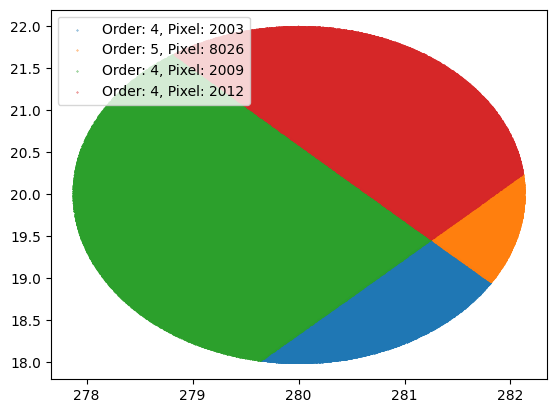

In [33]:
pixels = gaia3.get_healpix_pixels()
print(pixels)
for px in range(0,len(pixels)):
    pix = pixels[px]
    ordr = pix[0]
    pixl = pix[1]
    gtest = gaia3.get_partition(ordr,pixl)
    gtest.compute()
    print(f"ra range = {min(gtest['ra'])} - {max(gtest['ra'])}, dec range = {min(gtest['dec'])} - {max(gtest['dec'])}")
    plt.scatter(gtest['ra'],gtest['dec'],s=0.1,label=str(pix))
plt.legend()
plt.show()


# Try mapping function to multiple partitions in a catalog

In [35]:
t0 = time.time()
gaia3_lookup = gaia3.map_partitions(lookup_minipix_idx,lookup,"ra","dec",False)
t1 = time.time()
gaia3_lookup_data = gaia3_lookup.compute()
t2 = time.time()
print(f"Time to lookup for larger gaia chunk = {(t1-t0):.4f} seconds")
print(f"Time to compute resulting df = {(t2-t1):.4f} seconds")
gaia3_lookup_data

Time to lookup for larger gaia chunk = 0.0411 seconds
Time to compute resulting df = 24.7269 seconds


,source_id,ra,dec,phot_g_mean_mag,tile_id,minipix_idx
_healpix_29,,,,,,
1009407200355012427,2018814403590914432,290.607884,21.184409,19.35532,325991,1663
1009407200417976354,2018814403590914304,290.60835,21.184865,19.527374,325991,1663
...,...,...,...,...,...,...
2294660226583640192,4589320440092496768,273.848816,28.279731,20.433195,346090,3264
2294671971371937643,4589343942152809216,273.868609,28.293559,19.527416,346090,3392


In [37]:
t0 = time.time()
atlas_lookup = atlas.map_partitions(lookup_minipix_idx,lookup,"ra","dec",False)
t1 = time.time()
#gaia3_lookup_data = gaia3_lookup.compute()
#t2 = time.time()
print(f"Time to lookup for entire HATSed 0.1% of ATLAS = {(t1-t0):.4f} seconds")
#print(f"Time to compute resulting df = {(t2-t1):.4f} seconds")

Time to lookup for entire HATSed 0.1% of ATLAS = 0.0315 seconds


# Access PS1, Gaia thru LSDB data cloud

https://data.lsdb.io/#Pan-STARRS/Pan-STARRS1_(objects)

https://data.lsdb.io/#Gaia/Gaia_DR3_(US-East,_S3)


In [ ]:
arg_lim_mag = 20.5 # Argus limiting mag goal for 60sec cadence 

: 

In [ ]:
ps1_path = "s3://stpubdata/panstarrs/ps1/public/hats/otmo"
ps1_cols = ["objID","raMean","raMeanErr","decMean","decMeanErr","pmra","pmraErr","pmdec","pmdecErr",
            "nDetections","ng","nr","ni",
            "gMeanPSFMag","gMeanPSFMagErr","gMeanApMag","gMeanApMagErr",
            "rMeanPSFMag","rMeanPSFMagErr","rMeanApMag","rMeanApMagErr",
            "iMeanPSFMag","iMeanPSFMagErr","iMeanApMag","iMeanApMagErr"]
ps1 = lsdb.open_catalog(ps1_path,columns=ps1_cols,filters=[["gMeanApMag", "<", arg_lim_mag],["gMeanApMag", ">", 19]])

: 

In [ ]:
len(ps1)

10560724292

: 

In [ ]:
gaia_path = "s3://stpubdata/gaia/gaia_dr3/public/hats"
gaia_cols = ["source_id","ra","ra_error","dec","dec_error","pm","pmra","pmra_error","pmdec","pmdec_error",
             "phot_g_n_obs","phot_bp_n_obs",
             "phot_g_mean_mag","phot_bp_mean_mag"]
gaia = lsdb.open_catalog(gaia_path,columns=gaia_cols)

: 

# Activating Segments from a Source Catalog

Activate minipix coressponding to a given catalog of sources.

(from the __[Survey Initialization](https://github.com/argus-hdps/hdps/blob/main/docs/source/concepts/sky_tiling.rst#survey-initialization)__ section of the sky tiling concepts doc)

In [2]:
import astropy.units as u
from hdps.skymap import TanSegmentActivationManager, TanSegmentLookup
import lsdb
import pandas as pd

# Get a source catalog:

# - let's load my HATSed 0.1% of ATLAS with lsdb
atlas_path = "/net/scratch/kmfas/atlas_refcat2/atlas_0_01"

# - single partition for trying out lookup
ordr = 3 
pixid = 368 
atlas_pix_lookup = lsdb.open_catalog(atlas_path,search_filter=lsdb.PixelSearch((ordr,pixid))) #PixelSearch((order,pixelid))
atlas_single_part = atlas_pix_lookup.compute()
print(f"Single partition of HATSed 0.1% of ATLAS lazily and fully loaded ({len(atlas_single_part)} rows)")

# - entire cat for applying lookup as a function with map_partitions()
atlas_full = lsdb.open_catalog(atlas_path)
print(f"Entire HATSed 0.1% of ATLAS lazily loaded")

Computing Catalog:   0%|          | 0/49 [00:00<?, ?it/s]

Single partition of HATSed 0.1% of ATLAS lazily and fully loaded (9993 rows)
Entire HATSed 0.1% of ATLAS lazily loaded


In [7]:
# Define a TanSeg Lookup
# - assume source_catalog has RA, Dec columns

tile_size_default = 1800.0  # 2048 * (900/1024)       arcsec
overlap_arcsec_default = 28.125  # 32 * (900/1024)    arcsec
pixel_scale_default = 900 / 1024                    # arcsec

lookup = TanSegmentLookup(
    spacing_deg=(tile_size_default-overlap_arcsec_default)/3600,     # tile_size - overlap in degrees
    pixel_scale_deg=pixel_scale_default/3600                         # arcsec to degrees
    )

# Lookup tile/minipix ids & assign appropriate columns 
tanseg_ids, local_indices = lookup.query_batch(atlas_single_part['ra'],atlas_single_part['dec'])
atlas_single_part['tanseg_id'] = tanseg_ids
atlas_single_part['local_idx'] = local_indices

# Initialize all segments containing sources (100-year default activation)
manager = TanSegmentActivationManager("./data/aic_base_minipix/")
manager.initialize_from_source_catalog(
    atlas_single_part,
    tanseg_column='tanseg_id',
    local_idx_column='local_idx',
    default_duration=100 * u.year,
)

# see how many minipix are active for a given tile
tile_id = 270906
active = manager.get_active_minipixes(tanseg_id=tile_id)
print(f"{len(active)} minipixes active")

Initializing storage for sources in catalog
  TAN Segment 263703: activating 21 minipixes
  TAN Segment 265143: activating 32 minipixes
  TAN Segment 263702: activating 2 minipixes
  TAN Segment 265142: activating 24 minipixes
  TAN Segment 265144: activating 20 minipixes
  TAN Segment 266584: activating 29 minipixes
  TAN Segment 266583: activating 27 minipixes
  TAN Segment 266582: activating 32 minipixes
  TAN Segment 265145: activating 2 minipixes
  TAN Segment 266585: activating 37 minipixes
  TAN Segment 268025: activating 56 minipixes
  TAN Segment 268024: activating 35 minipixes
  TAN Segment 268023: activating 32 minipixes
  TAN Segment 265141: activating 4 minipixes
  TAN Segment 266581: activating 28 minipixes
  TAN Segment 268022: activating 32 minipixes
  TAN Segment 268021: activating 28 minipixes
  TAN Segment 266580: activating 11 minipixes
  TAN Segment 268020: activating 13 minipixes
  TAN Segment 269464: activating 36 minipixes
  TAN Segment 269463: activating 36 min